# Genre Classifier

## Imports

In [2]:
import numpy as np
import pandas as pd
from pydiffmap import diffusion_map
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 7)

/opt/anaconda3/lib/python3.9/site-packages/scipy/__init__.py:132: UserWarning: A NumPy version >=1.21.6 and <1.28.0 is required for this version of SciPy (detected version 1.21.5)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


## Data

### Metadata

In [3]:
# Load in tracks metadata
metadata_path = "fma_data/fma_metadata/tracks.csv"
tracks = pd.read_csv(metadata_path, low_memory=False)
tracks.head()

,Unnamed: 0,album,album.1,album.2,album.3,album.4,album.5,album.6,album.7,album.8,...,track.10,track.11,track.12,track.13,track.14,track.15,track.16,track.17,track.18,track.19
0,NaN,comments,date_created,date_released,engineer,favorites,id,information,listens,producer,...,information,interest,language_code,license,listens,lyricist,number,publisher,tags,title
1,track_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0,2008-11-26 01:44:45,2009-01-05 00:00:00,NaN,4,1,<p></p>,6073,NaN,...,NaN,4656,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1293,NaN,3,NaN,[],Food
3,3,0,2008-11-26 01:44:45,2009-01-05 00:00:00,NaN,4,1,<p></p>,6073,NaN,...,NaN,1470,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,514,NaN,4,NaN,[],Electric Ave
4,5,0,2008-11-26 01:44:45,2009-01-05 00:00:00,NaN,4,1,<p></p>,6073,NaN,...,NaN,1933,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1151,NaN,6,NaN,[],This World


In [4]:
# Change first row to header row
new_header = tracks.iloc[0]
tracks = tracks[1:]
tracks.columns = new_header
tracks = tracks.rename(columns={np.nan:'track_id'})
tracks.head()

,track_id,comments,date_created,date_released,engineer,favorites,id,information,listens,producer,...,information,interest,language_code,license,listens,lyricist,number,publisher,tags,title
1,track_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0,2008-11-26 01:44:45,2009-01-05 00:00:00,NaN,4,1,<p></p>,6073,NaN,...,NaN,4656,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1293,NaN,3,NaN,[],Food
3,3,0,2008-11-26 01:44:45,2009-01-05 00:00:00,NaN,4,1,<p></p>,6073,NaN,...,NaN,1470,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,514,NaN,4,NaN,[],Electric Ave
4,5,0,2008-11-26 01:44:45,2009-01-05 00:00:00,NaN,4,1,<p></p>,6073,NaN,...,NaN,1933,en,Attribution-NonCommercial-ShareAlike 3.0 Inter...,1151,NaN,6,NaN,[],This World
5,10,0,2008-11-26 01:45:08,2008-02-06 00:00:00,NaN,4,6,NaN,47632,NaN,...,NaN,54881,en,Attribution-NonCommercial-NoDerivatives (aka M...,50135,NaN,1,NaN,[],Freeway


In [5]:
# Extract list of tracks in small subset
small_subset = tracks.loc[ tracks['subset'] == 'small']
small_subset_id = small_subset['track_id']
small_subset_gen_id = small_subset[['track_id', 'genre_top']].reset_index(drop=True)

In [6]:
# Encode genres
genres = small_subset_gen_id['genre_top'].unique()
genre_map = { genre:value for genre, value in zip(genres, range(8)) }
small_subset_gen_id['genre_map'] = small_subset_gen_id.loc[:, 'genre_top'].map(genre_map)

# View
small_subset_gen_id

,track_id,genre_top,genre_map
0,2,Hip-Hop,0
1,5,Hip-Hop,0
2,10,Pop,1
3,140,Folk,2
4,141,Folk,2
...,...,...,...
7995,154308,Hip-Hop,0
7996,154309,Hip-Hop,0
7997,154413,Pop,1
7998,154414,Pop,1


In [7]:
# List of genres
print(genres)

['Hip-Hop' 'Pop' 'Folk' 'Experimental' 'Rock' 'International' 'Electronic'
 'Instrumental']


## Features Data

In [8]:
# Load in features
data_path = "fma_data/fma_metadata/features.csv"
features = pd.read_csv(data_path, low_memory=False)
features.head()

,feature,chroma_cens,chroma_cens.1,chroma_cens.2,chroma_cens.3,chroma_cens.4,chroma_cens.5,chroma_cens.6,chroma_cens.7,chroma_cens.8,...,tonnetz.39,tonnetz.40,tonnetz.41,zcr,zcr.1,zcr.2,zcr.3,zcr.4,zcr.5,zcr.6
0,statistics,kurtosis,kurtosis,kurtosis,kurtosis,kurtosis,kurtosis,kurtosis,kurtosis,kurtosis,...,std,std,std,kurtosis,max,mean,median,min,skew,std
1,number,01,02,03,04,05,06,07,08,09,...,04,05,06,01,01,01,01,01,01,01
2,track_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,7.1806526184e+00,5.2303090096e+00,2.4932080507e-01,1.3476201296e+00,1.4824777842e+00,5.3137123585e-01,1.4815930128e+00,2.6914546490e+00,8.6686819792e-01,...,5.4125156254e-02,1.2225749902e-02,1.2110591866e-02,5.7588901520e+00,4.5947265625e-01,8.5629448295e-02,7.1289062500e-02,0.0000000000e+00,2.0898721218e+00,6.1448108405e-02
4,3,1.8889633417e+00,7.6053929329e-01,3.4529656172e-01,2.2952005863e+00,1.6540306807e+00,6.7592434585e-02,1.3668476343e+00,1.0540937185e+00,1.0810308903e-01,...,6.3831120729e-02,1.4211839065e-02,1.7740072682e-02,2.8246941566e+00,4.6630859375e-01,8.4578499198e-02,6.3964843750e-02,0.0000000000e+00,1.7167237997e+00,6.9330163300e-02


In [9]:
# All features
all_features = features.copy()
all_features = all_features.loc[ all_features['feature'].isin(small_subset_id) ]
all_features = all_features.astype({key:'float64' for key in all_features.columns})

In [10]:
# Extract only mean values, keep feature column
mean_features = features.copy()
mean_features = mean_features.loc[:, features.loc[0].isin(['mean', 'std', 'skew']) ]
mean_features['feature'] = features.loc[:, 'feature']
mean_features = mean_features.loc[ mean_features['feature'].isin(small_subset_id) ]
mean_features = mean_features.rename(columns={'feature':'track_id'})
mean_features = mean_features.reset_index(drop=True)

In [11]:
# Drop particular features using regex on column names
import re

# Reduce feature set
columns = list(mean_features.columns)
drop_columns = [x for x in columns if re.match('chroma_cens|chroma_stft', x)]
mean_features = mean_features.drop(columns = drop_columns)
mean_features = mean_features.astype({key:'float64' for key in mean_features.columns})

## Standardize features data

In [12]:
standardized = mean_features.drop(columns=['track_id'])
standardized = (standardized - standardized.mean() )/standardized.std()

Scaling on data is very different accross different features.  Important to level the playing field before using the features together in any way.

In [13]:
standardized

,chroma_cqt.24,chroma_cqt.25,chroma_cqt.26,chroma_cqt.27,chroma_cqt.28,chroma_cqt.29,chroma_cqt.30,chroma_cqt.31,chroma_cqt.32,chroma_cqt.33,...,tonnetz.35,tonnetz.36,tonnetz.37,tonnetz.38,tonnetz.39,tonnetz.40,tonnetz.41,zcr.2,zcr.5,zcr.6
0,2.842066,1.529635,0.245225,0.059191,-0.023574,0.190548,0.245179,0.081053,-0.393150,-0.562602,...,-3.174346,-1.373105,-0.232702,-1.733645,-1.338259,-1.638771,-1.712701,1.220827,-0.482451,0.814345
1,0.283636,1.080324,0.227587,0.016942,0.214530,0.292256,0.742904,0.988384,1.566566,0.722904,...,-1.975630,-0.655706,-1.250755,-0.515329,-1.701203,-1.559180,-1.256912,0.079278,-0.447538,0.173108
2,0.167972,1.195492,0.368752,0.472986,-0.124114,1.228120,3.320220,1.756368,1.084849,0.664038,...,0.843942,-1.172739,0.058500,-0.430629,-0.790041,-0.658735,-1.401073,0.935927,0.007833,0.016152
3,-0.936661,-0.028031,0.491241,-0.129840,-0.069940,0.025488,-0.736885,-0.722858,0.418905,0.660036,...,-0.988937,0.827556,0.701480,0.205410,1.467714,1.073012,0.668253,0.053455,-0.126634,0.669933
4,-1.161403,-1.240319,-0.563842,-0.294681,-0.158839,0.334370,-0.231776,-0.936670,-1.135570,0.230914,...,0.453563,1.175273,0.338404,1.512927,1.150976,0.434995,1.729334,-0.371753,0.231219,-0.452977
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,-0.574354,0.467919,-0.912365,-1.643354,-1.316655,-0.367794,0.523312,-0.527624,0.386076,0.747591,...,-0.795423,1.110946,1.136719,0.201064,0.373141,0.017999,-0.010895,-0.275896,1.150820,1.697661
7996,-0.922234,-1.139642,-0.111311,0.360794,0.495747,0.230580,1.077967,0.651339,-0.876174,-1.640904,...,1.410518,0.493911,1.932880,0.116239,2.083141,1.284049,0.294013,1.127760,-0.026285,3.444307
7997,0.886077,-0.192634,-1.037328,-1.484529,-1.238539,-1.082478,-1.153686,-1.179483,-1.463480,-1.511815,...,1.139354,1.967701,3.998148,1.824901,1.438003,2.588638,2.762217,-0.924189,0.073428,-0.640236
7998,-0.704442,-0.937314,-0.814855,0.476568,1.350367,-0.383411,-1.403851,-1.275117,-1.009647,-0.950320,...,-0.403097,1.926467,0.414152,1.077705,2.107452,0.842362,1.534626,-0.166394,0.161330,0.206847


## Diff Map Dimensionality reduction

In [88]:
# Instantiate diffmap object
diff_map = diffusion_map.DiffusionMap.from_sklearn(n_evecs = 2, 
                                                   epsilon = 300,
                                                   alpha = .06, 
                                                   k=60,
                                                   kernel_type = 'gaussian')

In [89]:
# Fit diff map
diff_map.fit( standardized.to_numpy() )

# Extract e-vec coordinates
coords = diff_map.fit_transform( standardized.to_numpy() )

# Add e-vec coordinates to metadata
small_subset_gen_id.loc[:, ['e0', 'e1']] = coords

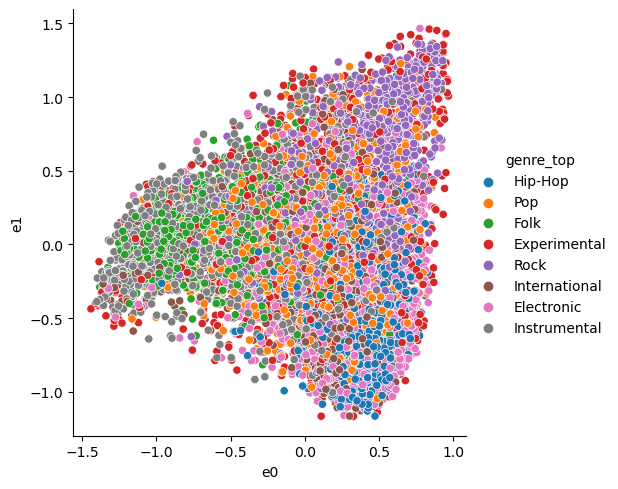

In [90]:
# Plot e-vecs
sns.relplot(data=small_subset_gen_id,
            x = 'e0',
            y = 'e1',
            hue = 'genre_top'
           )

## Genre Classification

In [91]:
# Fit model using KNN
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=10, weights='uniform')
neigh.fit(coords, small_subset_gen_id['genre_top'])
predictions = neigh.predict(coords)

# Prediciton accuracy
acc = sum( predictions == small_subset_gen_id['genre_top'] )/8000
print(acc)

0.4215


In [92]:
# Chance odds of classification
1/len(genres)

0.125

### What genres got confused the most?

In [93]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(small_subset_gen_id['genre_top'] , predictions, labels=genres, normalize='true')

<AxesSubplot:>

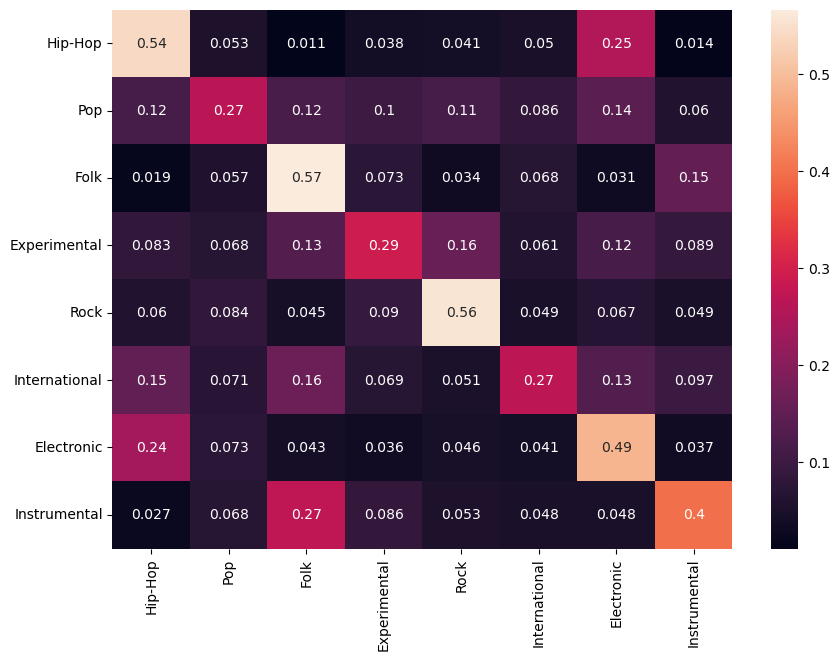

In [94]:
sns.heatmap(cm, annot=True, xticklabels=genres, yticklabels=genres)